In [1]:
from pathlib import Path

sample_dir = Path("/data/bvcoe2026/CMS-OD/samples")

print("Directory exists:", sample_dir.exists())

if sample_dir.exists():
    root_files = sorted(sample_dir.glob("*.root"))
    print("Number of ROOT files:", len(root_files))

    for file in root_files:
        print(file.name)
else:
    print("Sample directory not found.")

Directory exists: True
Number of ROOT files: 8
DY-test.root
DY-train.root
Higgs-test.root
Higgs-train.root
Top-test.root
Top-train.root
WW-test.root
WW-train.root


In [2]:
import uproot

file_path = str(root_files[0])

with uproot.open(file_path) as f:
    print("Objects inside file:")
    print(f.keys())

Objects inside file:
['Events;1']


In [3]:
with uproot.open(file_path) as f:
    tree = f["Events"]

    print("Total events:", tree.num_entries)
    print("Available branches:")
    print(tree.keys())

Total events: 90090
Available branches:
['Jet1_eta', 'Jet1_phi', 'Jet1_pt', 'Jet2_eta', 'Jet2_phi', 'Jet2_pt', 'Lepton1_eta', 'Lepton1_phi', 'Lepton1_pt', 'Lepton2_eta', 'Lepton2_phi', 'Lepton2_pt', 'PuppiMET_phi', 'PuppiMET_pt', 'dphill', 'jet_cat', 'mjj', 'mll', 'mth', 'mtw2', 'njet', 'ptll']


In [4]:
with uproot.open(file_path) as f:
    tree = f["Events"]

    for name in tree.keys():
        if any(x in name for x in ["Muon_pt", "Electron_pt", "Jet_pt", "MET_pt"]):
            print(name)

PuppiMET_pt


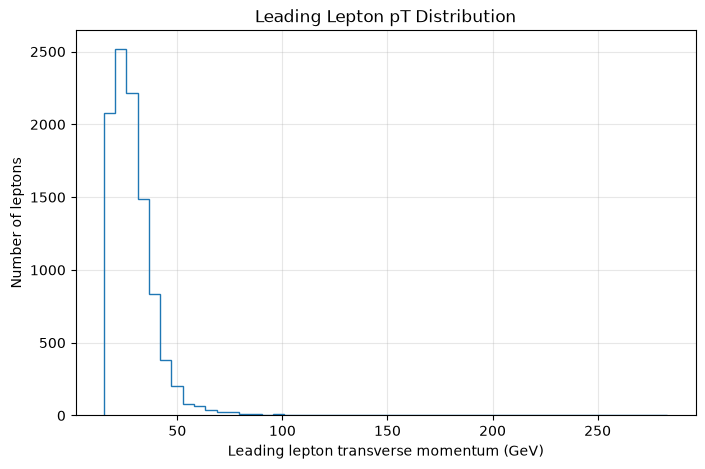

In [5]:
import uproot
import matplotlib.pyplot as plt

with uproot.open(file_path) as f:
    tree = f["Events"]
    values = tree["Lepton1_pt"].array(
        entry_stop=10000,
        library="ak"
    )

plt.figure(figsize=(8, 5))
plt.hist(values, bins=50, histtype="step")
plt.xlabel("Leading lepton transverse momentum (GeV)")
plt.ylabel("Number of leptons")
plt.title("Leading Lepton pT Distribution")
plt.grid(alpha=0.3)
plt.show()

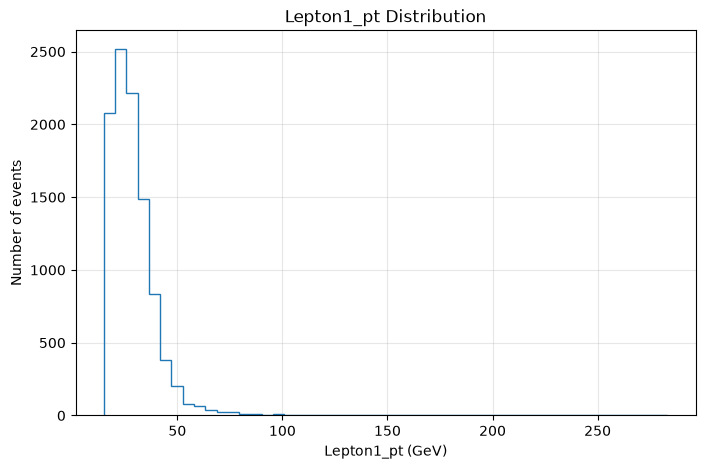

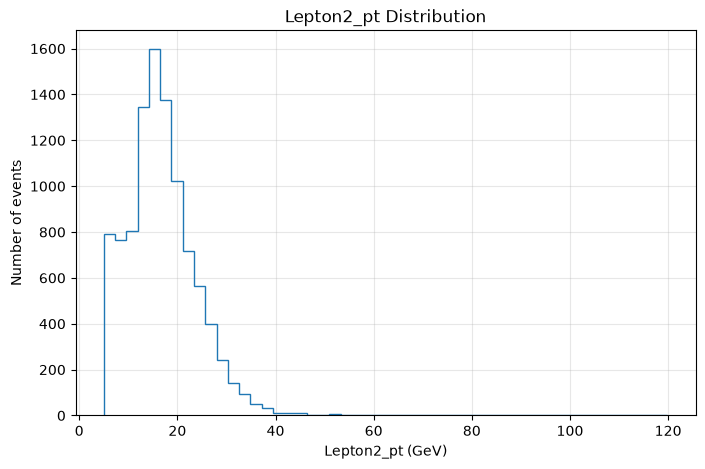

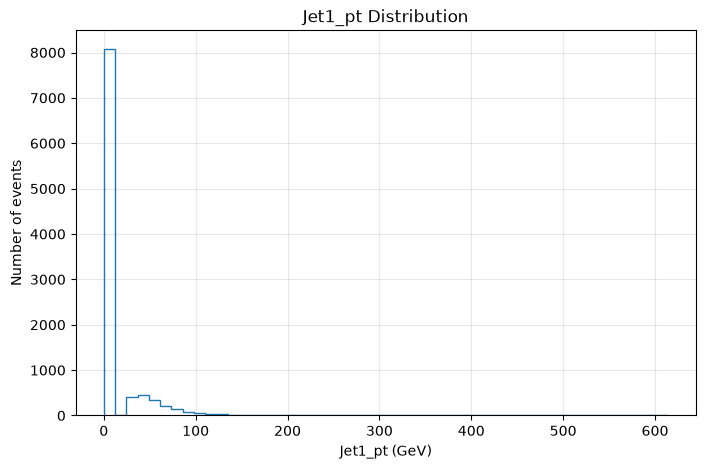

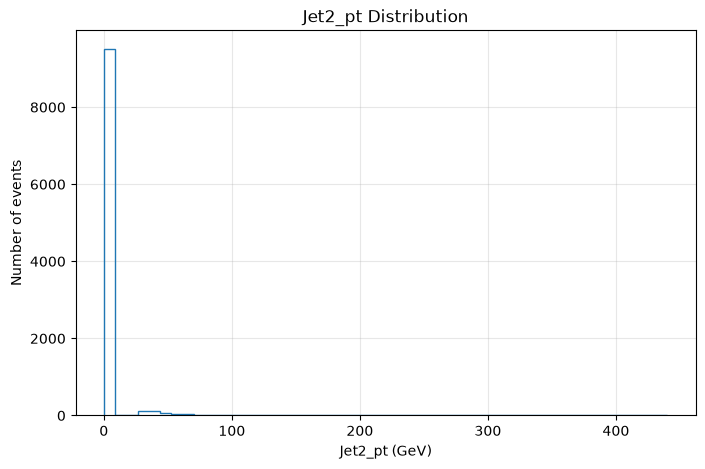

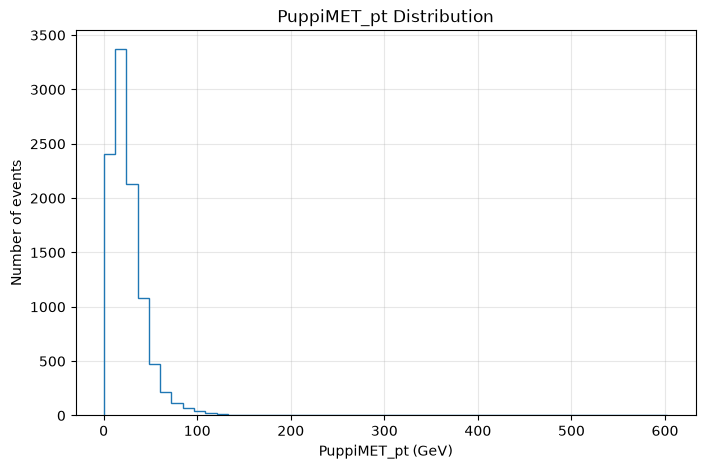

In [6]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt

variables = ["Lepton1_pt", "Lepton2_pt", "Jet1_pt", "Jet2_pt", "PuppiMET_pt"]

with uproot.open(file_path) as f:
    tree = f["Events"]

    for variable in variables:
        if variable not in tree.keys():
            print("Skipping missing branch:", variable)
            continue

        arr = tree[variable].array(
            entry_stop=10000,
            library="ak"
        )
        values = ak.to_numpy(arr)

        plt.figure(figsize=(8, 5))
        plt.hist(values, bins=50, histtype="step")
        plt.xlabel(f"{variable} (GeV)")
        plt.ylabel("Number of events")
        plt.title(f"{variable} Distribution")
        plt.grid(alpha=0.3)
        plt.show()

Found DY: /data/bvcoe2026/CMS-OD/samples/DY-train.root
Found Higgs: /data/bvcoe2026/CMS-OD/samples/Higgs-train.root
Found Top: /data/bvcoe2026/CMS-OD/samples/Top-train.root
Found WW: /data/bvcoe2026/CMS-OD/samples/WW-train.root


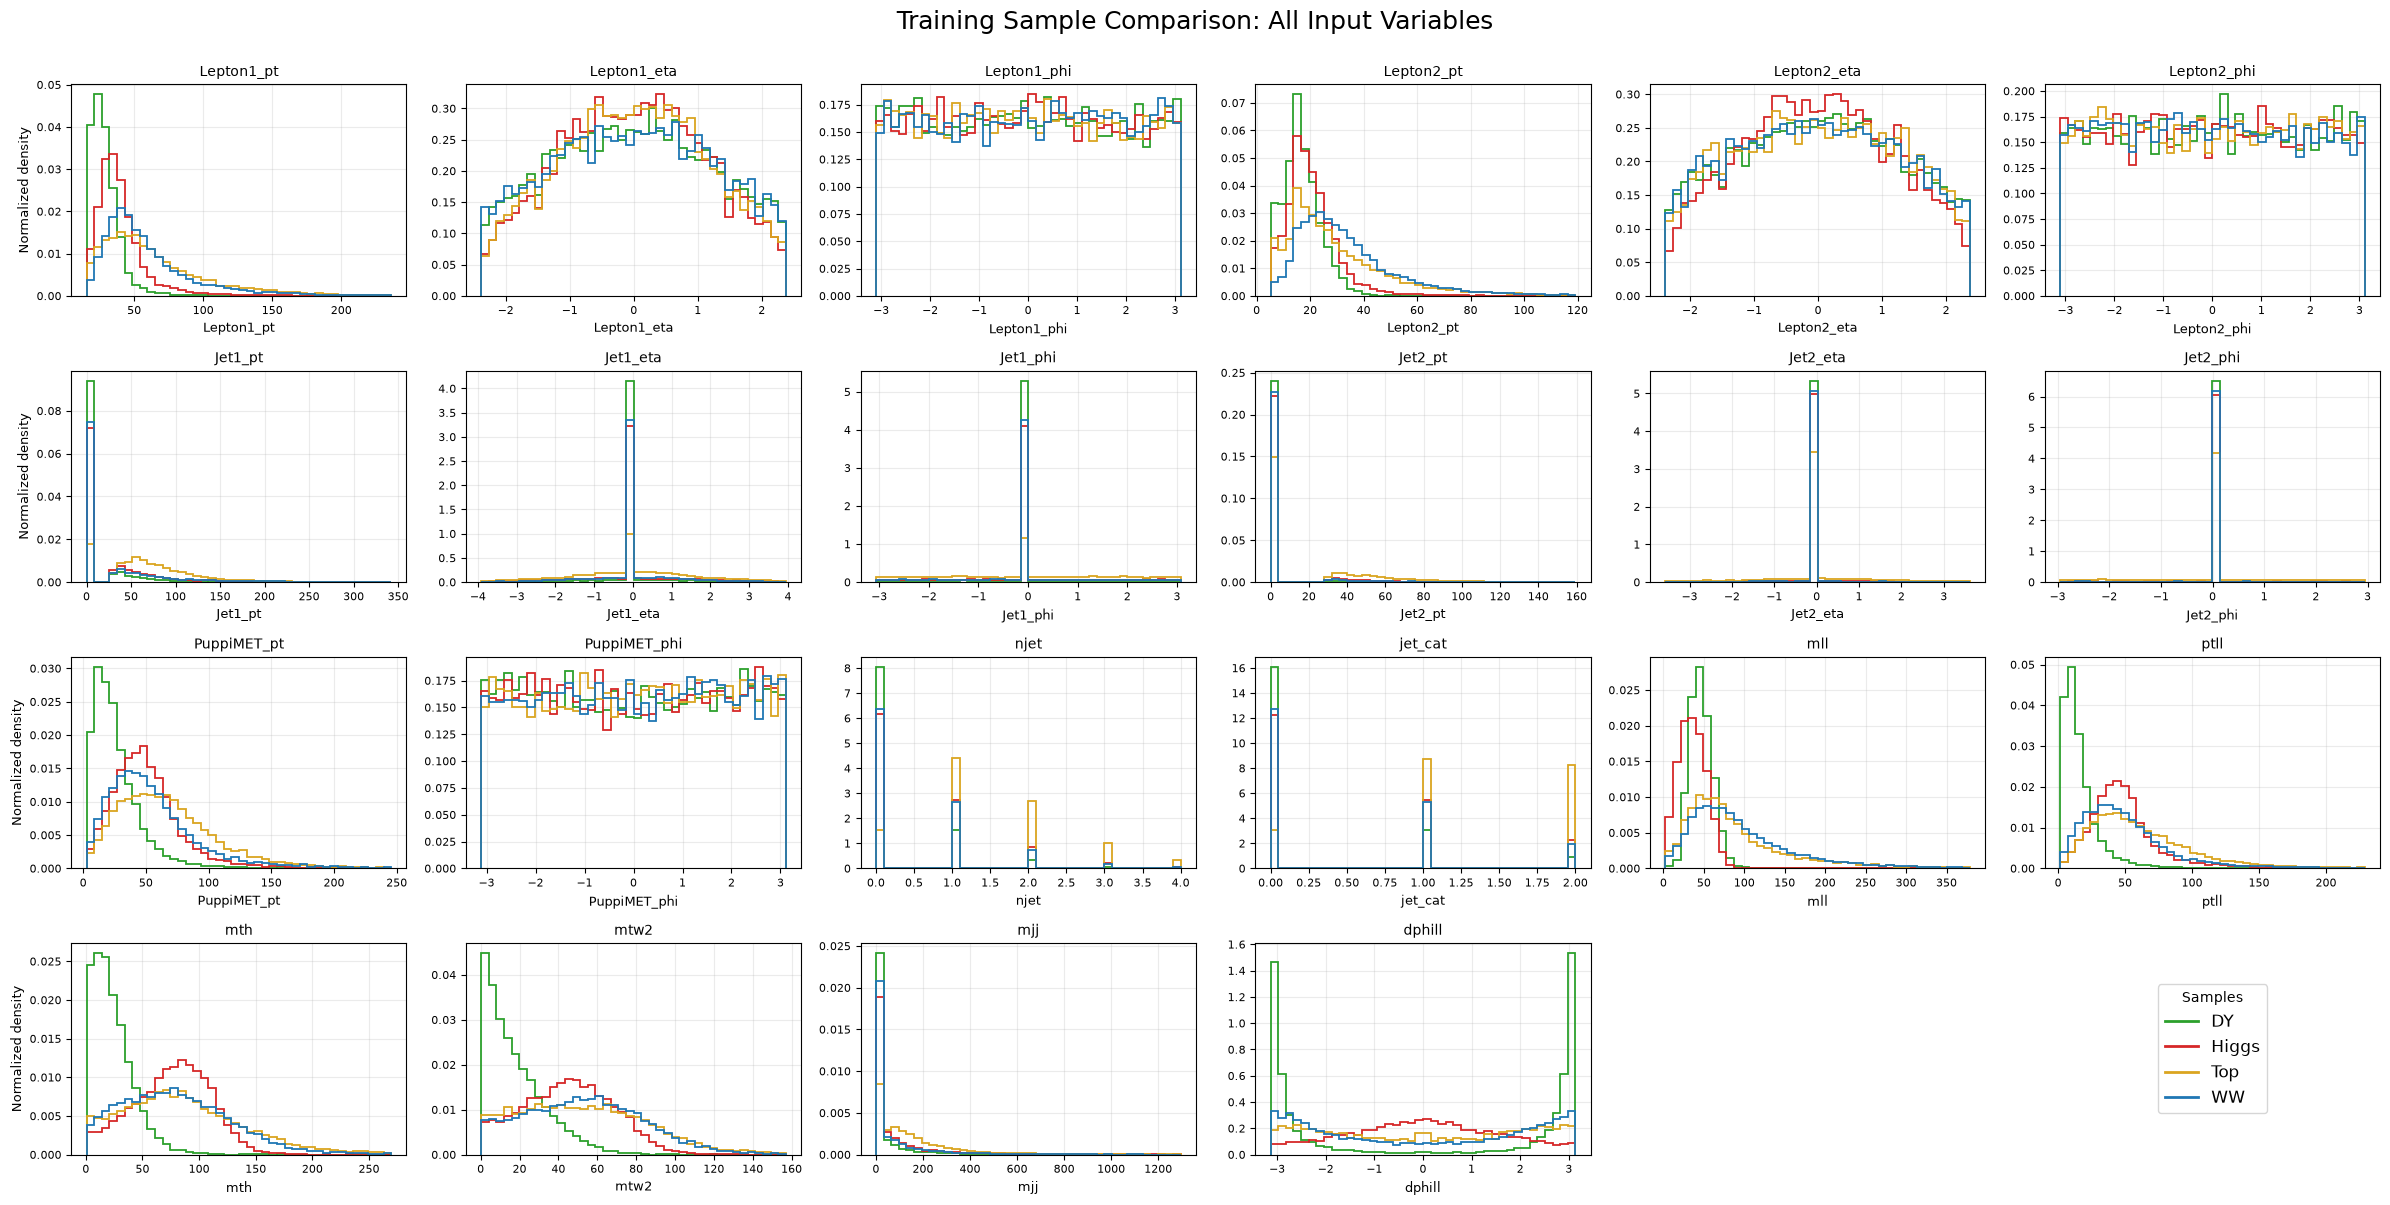


Plots saved in: /home/jovyan/Untitled Folder/superimposed_plots


In [7]:
from pathlib import Path
import math
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

sample_dir = Path("/data/bvcoe2026/CMS-OD/samples")

sample_files = {
    "DY": sample_dir / "DY-train.root",
    "Higgs": sample_dir / "Higgs-train.root",
    "Top": sample_dir / "Top-train.root",
    "WW": sample_dir / "WW-train.root",
}

# Branch names that exist in the flat ntuple (missing ones are skipped automatically)
mvaVariables = [
    "Lepton1_pt", "Lepton1_eta", "Lepton1_phi",
    "Lepton2_pt", "Lepton2_eta", "Lepton2_phi",
    "Jet1_pt", "Jet1_eta", "Jet1_phi",
    "Jet2_pt", "Jet2_eta", "Jet2_phi",
    "PuppiMET_pt", "PuppiMET_phi",
    "njet", "jet_cat",
    "mll", "ptll", "mth", "mtw2", "mjj", "dphill",
]

output_dir = Path("superimposed_plots")
output_dir.mkdir(parents=True, exist_ok=True)

N_COLS = 6          # panels per row
N_BINS = 40
ENTRY_STOP = 10000  # events read per sample
PLACEHOLDER_CUT = -999  # drop sentinel values such as -9999

colors = {"DY": "tab:green", "Higgs": "tab:red",
          "Top": "goldenrod", "WW": "tab:blue"}

# ---- Locate sample files ----
available_samples = {}
for label, path in sample_files.items():
    if path.exists():
        available_samples[label] = path
        print(f"Found {label}: {path}")
    else:
        print(f"MISSING {label}: {path}")

if len(available_samples) < 2:
    raise FileNotFoundError("Need at least two sample files.")

# ---- Open trees ----
trees = {}
for label, path in available_samples.items():
    root_file = uproot.open(path)
    if "Events" not in root_file:
        print(f"Skipping {label}: no Events tree")
        root_file.close()
        continue
    trees[label] = (root_file, root_file["Events"])

# ---- Keep only variables present in at least two samples ----
keys = {label: set(tree.keys()) for label, (_, tree) in trees.items()}
plot_vars = []
for v in mvaVariables:
    n_found = sum(v in k for k in keys.values())
    if n_found >= 2:
        plot_vars.append(v)
    else:
        print(f"Skipping {v}: found in {n_found} sample(s)")

if not plot_vars:
    raise ValueError("None of the requested variables were found.")

# ---- Grid layout (+1 slot for the legend) ----
n_slots = len(plot_vars) + 1
n_rows = math.ceil(n_slots / N_COLS)

fig, axes = plt.subplots(n_rows, N_COLS, figsize=(4 * N_COLS, 3 * n_rows))
axes = axes.ravel()

for panel, variable in enumerate(plot_vars):
    # Read each sample's values for this variable
    data = {}
    for label, (root_file, tree) in trees.items():
        if variable not in keys[label]:
            continue
        try:
            arr = tree[variable].array(entry_stop=ENTRY_STOP, library="ak")
            vals = ak.to_numpy(ak.flatten(arr, axis=None)).astype(float)
            vals = vals[np.isfinite(vals) & (vals > PLACEHOLDER_CUT)]
            if len(vals) > 0:
                data[label] = vals
        except Exception as exc:
            print(f"Could not read {variable} from {label}: {exc}")

    ax = axes[panel]
    if len(data) < 2:
        ax.axis("off")
        continue

    # Common bin edges for all samples (clip extreme outliers)
    allvals = np.concatenate(list(data.values()))
    lo, hi = np.percentile(allvals, [0.5, 99.5])
    if lo == hi:
        lo, hi = lo - 0.5, hi + 0.5
    bins = np.linspace(lo, hi, N_BINS + 1)

    for label, vals in data.items():
        ax.hist(vals, bins=bins, histtype="step", density=True,
                linewidth=1.3, color=colors.get(label))

    ax.set_xlabel(variable, fontsize=9)
    ax.set_title(variable, fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.25)
    if panel % N_COLS == 0:
        ax.set_ylabel("Normalized density", fontsize=9)

# ---- Legend in the last slot ----
legend_ax = axes[-1]
legend_ax.axis("off")
handles = [Line2D([0], [0], color=colors.get(l), lw=2, label=l)
           for l in trees.keys()]
legend_ax.legend(handles=handles, loc="center", fontsize=12, title="Samples")

# ---- Hide unused panels between the last plot and the legend ----
for ax in axes[len(plot_vars):-1]:
    ax.axis("off")

fig.suptitle("Training Sample Comparison: All Input Variables",
             fontsize=18, y=1.0)
fig.tight_layout()
fig.savefig(output_dir / "all_variables_grid.png", dpi=150, bbox_inches="tight")
fig.savefig(output_dir / "all_variables_grid.pdf", bbox_inches="tight")
plt.show()

for root_file, tree in trees.values():
    root_file.close()

print(f"\nPlots saved in: {output_dir.resolve()}")

In [8]:
import uproot
%pip install seaborn
import seaborn as sns
import numpy as np
import pandas as pd
import uproot
import awkward as ak
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc, roc_auc_score

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# ============================================================
# CELL 8: Global Configuration & Feature Definitions
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.metrics import roc_curve, auc, roc_auc_score
try:
    from xgboost import XGBClassifier
    print('XGBoost available')
except ImportError:
    from sklearn.ensemble import GradientBoostingClassifier
    print('XGBoost not available, using sklearn GradientBoostingClassifier')


# ── Paths & Hyperparameters ─────────────────────────────────
sample_dir  = Path("/data/bvcoe2026/CMS-OD/samples")
N_EVENTS    = 100_000   # events per sample (for balanced training & fast run)
RANDOM_SEED = 42

# XGBoost hyperparameters
XGB_PARAMS = dict(
    n_estimators      = 800,
    max_depth         = 6,
    learning_rate     = 0.05,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    min_child_weight  = 50,
    gamma             = 1.0,
    reg_alpha         = 0.1,
    reg_lambda        = 1.0,
    use_label_encoder = False,
    eval_metric       = 'auc',
    random_state      = RANDOM_SEED,
    n_jobs            = -1,
    verbosity         = 1,
)

# ── 19 Flat Kinematic Features ──────────────────────────────
FLAT_FEATURES = [
    # Event-level kinematics
    "dphill", "mll", "mjj", "mth", "mtw2", "ptll",
    "njet",
    "PuppiMET_pt", "PuppiMET_phi",
    # Leptons (leading / subleading)
    "Lepton1_pt", "Lepton1_eta", "Lepton1_phi",
    "Lepton2_pt", "Lepton2_eta", "Lepton2_phi",
    # Jets (leading / subleading)
    "Jet1_pt", "Jet1_eta", "Jet1_phi",
    "Jet2_pt",
]

JAGGED_FEATURES = {}
ALL_FEATURES = FLAT_FEATURES + list(JAGGED_FEATURES.keys())

# ── Sample Dictionaries: Train and Test Files Strictly Separated ─
TRAIN_SAMPLES = {
    "Higgs": (sample_dir / "Higgs-train.root", 1),  # signal
    "DY":    (sample_dir / "DY-train.root",    0),  # background
    "Top":   (sample_dir / "Top-train.root",   0),  # background
    "WW":    (sample_dir / "WW-train.root",    0),  # background
}

TEST_SAMPLES = {
    "Higgs": (sample_dir / "Higgs-test.root", 1),
    "DY":    (sample_dir / "DY-test.root",    0),
    "Top":   (sample_dir / "Top-test.root",   0),
    "WW":    (sample_dir / "WW-test.root",    0),
}

print("✓ Configuration ready.")
print(f"  Base features ({len(ALL_FEATURES)} total):", ALL_FEATURES)
print(f"  Events per sample (cap): {N_EVENTS:,}")
print(f"  XGBoost: {XGB_PARAMS['n_estimators']} trees, max_depth={XGB_PARAMS['max_depth']}, lr={XGB_PARAMS['learning_rate']}")

In [10]:
# ============================================================
# CELL 9: Data Loading Function
# ============================================================
def load_events(sample_dict, n_events=None):
    """
    Reads ROOT files, extracts ALL_FEATURES, and returns a DataFrame
    with 'label' and 'sample' columns. Missing values are filled with -999.
    """
    frames = []

    for name, (path, label) in sample_dict.items():
        if not path.exists():
            print(f"⚠ Missing file: {path}")
            continue

        print(f"Loading {name:6s} ...", end=" ")

        with uproot.open(path) as f:
            tree = f["Events"]

            # Validate branch availability
            missing = [feat for feat in ALL_FEATURES if feat not in tree.keys()]
            if missing:
                raise KeyError(
                    f"{name}: branches not found in {path.name}: {missing}\n"
                    f"Check spelling or remove from FLAT_FEATURES."
                )

            df = tree.arrays(
                expressions=ALL_FEATURES,
                entry_stop=n_events,
                library="pd"
            )

        df["label"]  = label
        df["sample"] = name
        df[ALL_FEATURES] = df[ALL_FEATURES].fillna(-999)

        frames.append(df)
        print(f"{len(df):>9,} events  (label={label})")

    return pd.concat(frames, ignore_index=True)

print("✓ load_events() defined successfully.")

✓ load_events() defined successfully.


In [11]:
print("Loading TRAINING data strictly...")
print("=" * 55)
df_train = load_events(TRAIN_SAMPLES, n_events=N_EVENTS)

X_train = df_train[ALL_FEATURES].values
y_train = df_train["label"].values

print()
print(f"Training set loaded: {len(X_train):>9,} events | "
      f"Signal: {y_train.sum():>7,} | Background: {(y_train == 0).sum():>7,}")
print("\nEvents per training sample:")
print(df_train["sample"].value_counts().to_string())
print("\n✓ Training data ready. No test data has been touched.")

Loading TRAINING data strictly...
Loading Higgs  ...    65,699 events  (label=1)
Loading DY     ...    80,621 events  (label=0)
Loading Top    ...    29,841 events  (label=0)
Loading WW     ...   100,000 events  (label=0)

Training set loaded:   276,161 events | Signal:  65,699 | Background: 210,462

Events per training sample:
sample
WW       100000
DY        80621
Higgs     65699
Top       29841

✓ Training data ready. No test data has been touched.


In [ ]:
# ============================================================
# CELL 10b: Physics-Motivated Feature Engineering
# ============================================================
import numpy as np

SENTINEL = -999.0

def add_physics_features(df):
    """Add derived physics-motivated features to the dataframe."""
    df = df.copy()
    
    # ── Helper: delta_phi in [-pi, pi] ──────────────────────
    def dphi(phi1, phi2):
        d = phi1 - phi2
        return np.where(d > np.pi, d - 2*np.pi,
               np.where(d < -np.pi, d + 2*np.pi, d))
    
    # ── Helper: delta_R = sqrt(deta^2 + dphi^2) ─────────────
    def deltaR(eta1, phi1, eta2, phi2):
        deta = eta1 - eta2
        dp   = dphi(phi1, phi2)
        return np.sqrt(deta**2 + dp**2)
    
    # ── Lepton-Lepton quantities ─────────────────────────────
    # dR(l1, l2) - angular separation between leptons
    df['dR_ll'] = deltaR(
        df['Lepton1_eta'], df['Lepton1_phi'],
        df['Lepton2_eta'], df['Lepton2_phi']
    )
    # pT ratio: subleading / leading lepton
    df['pt_ratio_ll'] = np.where(
        df['Lepton1_pt'] > 0,
        df['Lepton2_pt'] / df['Lepton1_pt'].clip(lower=1e-6),
        SENTINEL
    )
    # Sum of lepton pTs
    df['scalar_sum_pt_ll'] = df['Lepton1_pt'] + df['Lepton2_pt']
    
    # ── MET-Lepton quantities ────────────────────────────────
    # dphi(MET, l1), dphi(MET, l2)
    df['dphi_MET_l1'] = np.abs(dphi(df['PuppiMET_phi'], df['Lepton1_phi']))
    df['dphi_MET_l2'] = np.abs(dphi(df['PuppiMET_phi'], df['Lepton2_phi']))
    # MET / ptll ratio
    df['MET_over_ptll'] = np.where(
        df['ptll'] > 0,
        df['PuppiMET_pt'] / df['ptll'].clip(lower=1e-6),
        SENTINEL
    )
    
    # ── Jet quantities (only Jet1 eta/phi are available) ────
    # jet pT ratio: Jet2_pt / Jet1_pt (sentinel when Jet2 absent)
    jet1_valid = df['Jet1_pt'] > 0
    jet2_valid = df['Jet2_pt'] > 0
    
    df['jet_pt_ratio'] = np.where(
        jet1_valid & jet2_valid,
        df['Jet2_pt'] / df['Jet1_pt'].clip(lower=1e-6),
        SENTINEL
    )
    
    # ── Lepton-Jet quantities (only Jet1 has eta/phi) ───────
    # dR(l1, j1)
    df['dR_l1j1'] = np.where(
        jet1_valid,
        deltaR(df['Lepton1_eta'], df['Lepton1_phi'],
               df['Jet1_eta'],    df['Jet1_phi']),
        SENTINEL
    )
    # dR(l2, j1)
    df['dR_l2j1'] = np.where(
        jet1_valid,
        deltaR(df['Lepton2_eta'], df['Lepton2_phi'],
               df['Jet1_eta'],    df['Jet1_phi']),
        SENTINEL
    )
    # dphi(MET, j1)
    df['dphi_MET_j1'] = np.where(
        jet1_valid,
        np.abs(dphi(df['PuppiMET_phi'], df['Jet1_phi'])),
        SENTINEL
    )
    
    # ── Event-level ratios ───────────────────────────────────
    # mll / mth (invariant mass ratio)
    df['mll_over_mth'] = np.where(
        df['mth'] > 0,
        df['mll'] / df['mth'].clip(lower=1e-6),
        SENTINEL
    )
    # ptll / mll
    df['ptll_over_mll'] = np.where(
        df['mll'] > 0,
        df['ptll'] / df['mll'].clip(lower=1e-6),
        SENTINEL
    )
    # MET significance proxy: MET / sqrt(HT_ll)
    df['MET_sig'] = np.where(
        df['scalar_sum_pt_ll'] > 0,
        df['PuppiMET_pt'] / np.sqrt(df['scalar_sum_pt_ll'].clip(lower=1e-6)),
        SENTINEL
    )
    # Lepton centrality w.r.t Jet1 eta
    df['lep_centrality'] = np.where(
        jet1_valid,
        0.5 * (df['Lepton1_eta'] + df['Lepton2_eta']) - df['Jet1_eta'],
        SENTINEL
    )
    
    return df

# Apply feature engineering to training data
df_train_eng = add_physics_features(df_train)

# Define the engineered feature list
ENGINEERED_FEATURES = [
    'dR_ll', 'pt_ratio_ll', 'scalar_sum_pt_ll',
    'dphi_MET_l1', 'dphi_MET_l2', 'MET_over_ptll',
    'jet_pt_ratio', 'dR_l1j1', 'dR_l2j1', 'dphi_MET_j1',
    'mll_over_mth', 'ptll_over_mll', 'MET_sig', 'lep_centrality',
]

ALL_FEATURES_ENG = ALL_FEATURES + ENGINEERED_FEATURES

X_train_eng = df_train_eng[ALL_FEATURES_ENG].values
y_train      = df_train_eng['label'].values

print(f'Feature engineering complete.')
print(f'  Original features : {len(ALL_FEATURES)}')
print(f'  Engineered features: {len(ENGINEERED_FEATURES)}')
print(f'  Total features    : {len(ALL_FEATURES_ENG)}')
print(f'  Training shape    : {X_train_eng.shape}')


In [ ]:
# ============================================================
# CELL 11: XGBoost Model Training
# ============================================================
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    from sklearn.ensemble import GradientBoostingClassifier
    HAS_XGB = False

# Compute class weight to handle imbalance
n_sig = (y_train == 1).sum()
n_bkg = (y_train == 0).sum()
scale_pos_weight = n_bkg / n_sig
print(f'Signal: {n_sig:,}  Background: {n_bkg:,}  scale_pos_weight: {scale_pos_weight:.2f}')

if HAS_XGB:
    model = XGBClassifier(
        n_estimators      = 800,
        max_depth         = 6,
        learning_rate     = 0.05,
        subsample         = 0.8,
        colsample_bytree  = 0.8,
        min_child_weight  = 50,
        gamma             = 1.0,
        reg_alpha         = 0.1,
        reg_lambda        = 1.0,
        scale_pos_weight  = scale_pos_weight,
        eval_metric       = 'auc',
        random_state      = RANDOM_SEED,
        n_jobs            = -1,
        verbosity         = 0,
    )
    model_name = 'XGBoost'
else:
    # Fallback: sklearn GradientBoostingClassifier (slower but no xgb dependency)
    from sklearn.ensemble import GradientBoostingClassifier
    model = GradientBoostingClassifier(
        n_estimators  = 500,
        max_depth     = 5,
        learning_rate = 0.05,
        subsample     = 0.8,
        random_state  = RANDOM_SEED,
        verbose       = 1,
    )
    model_name = 'GradientBoosting (sklearn)'

print(f'Training {model_name} on {len(X_train_eng):,} events with {X_train_eng.shape[1]} features...')
model.fit(X_train_eng, y_train)

# Compute predictions on training data
score_train = model.predict_proba(X_train_eng)[:, 1]
auc_train_quick = roc_auc_score(y_train, score_train)

print(f'✓ {model_name} training complete!')
print(f'  Training AUC: {auc_train_quick:.4f}')

In [ ]:
print("Loading TEST data...")
print("=" * 55)
df_test = load_events(TEST_SAMPLES, n_events=N_EVENTS)

# Apply the same feature engineering to test data
df_test_eng = add_physics_features(df_test)

X_test = df_test_eng[ALL_FEATURES_ENG].values
y_test = df_test_eng["label"].values

print()
print(f"Test set loaded: {len(X_test):>9,} events | "
      f"Signal: {y_test.sum():>7,} | Background: {(y_test == 0).sum():>7,}")
print("\nEvents per test sample:")
print(df_test_eng["sample"].value_counts().to_string())

# Score test events using the already trained model
score_test = model.predict_proba(X_test)[:, 1]
df_test_eng["rf_score"] = score_test
df_test = df_test_eng  # alias for downstream cells

auc_test_quick = roc_auc_score(y_test, score_test)

print(f"  Train AUC : {auc_train_quick:.4f}")
print(f"  Test  AUC : {auc_test_quick:.4f}")
print(f"  AUC Gap   : {auc_train_quick - auc_test_quick:.4f}")

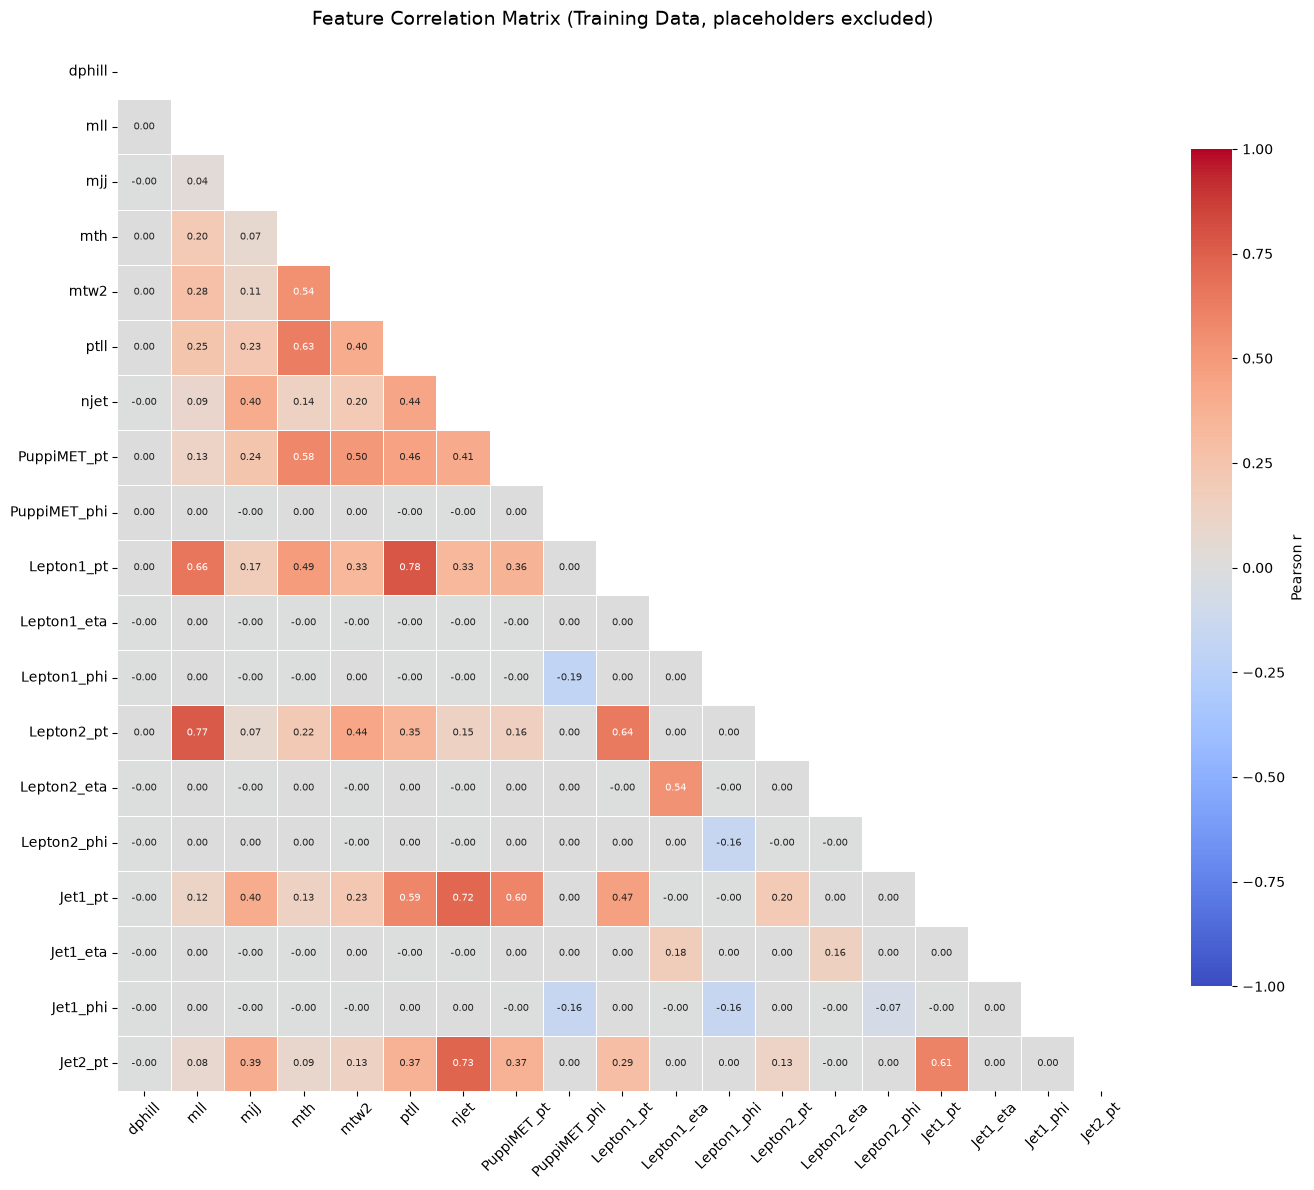

Strongly correlated feature pairs (|r| > 0.7):
  mll                       ↔  Lepton2_pt                 r = +0.767
  ptll                      ↔  Lepton1_pt                 r = +0.784
  njet                      ↔  Jet1_pt                    r = +0.722
  njet                      ↔  Jet2_pt                    r = +0.732


In [18]:
SENTINEL_CUT = -999   

df_feat = pd.DataFrame(X_train, columns=ALL_FEATURES)
df_feat = df_feat.where(df_feat > SENTINEL_CUT)   # sentinels -> NaN
corr    = df_feat.corr(method="pearson", min_periods=100)

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.4,
    ax=ax,
    annot_kws={"size": 7},
    cbar_kws={"label": "Pearson r", "shrink": 0.8},
)
ax.set_title("Feature Correlation Matrix (Training Data, placeholders excluded)",
             fontsize=14, pad=14)
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.savefig("feature_correlation_matrix.png", dpi=150)
plt.show()

print("Strongly correlated feature pairs (|r| > 0.7):")
cols = corr.columns
found = False
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr.iloc[i, j]
        if pd.notna(r) and abs(r) > 0.7:
            print(f"  {cols[i]:25s} ↔  {cols[j]:25s}  r = {r:+.3f}")
            found = True
if not found:
    print("  None found — all features have |r| ≤ 0.7")

In [1]:
fpr_train, tpr_train, _ = roc_curve(y_train, score_train)
fpr_test,  tpr_test,  _ = roc_curve(y_test,  score_test)

auc_train = auc(fpr_train, tpr_train)
auc_test  = auc(fpr_test,  tpr_test)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_train, tpr_train, color="royalblue", lw=2,
        label=f"Train AUC = {auc_train:.4f}")
ax.plot(fpr_test,  tpr_test,  color="tomato",    lw=2, linestyle="--",
        label=f"Test  AUC = {auc_test:.4f}")
ax.plot([0, 1], [0, 1], "k:", lw=1, label="Random (AUC = 0.5)")

# Mark working point at FPR = 0.30
idx = np.argmin(np.abs(fpr_test - 0.30))
ax.scatter(fpr_test[idx], tpr_test[idx], color="tomato", zorder=5,
           label=f"Test @ FPR=0.30 -> TPR={tpr_test[idx]:.2f}")

ax.set_xlabel("False Positive Rate (Background efficiency)", fontsize=12)
ax.set_ylabel("True Positive Rate (Signal efficiency)",     fontsize=12)
ax.set_title("ROC Curve - XGBoost: Higgs vs Background", fontsize=13)
ax.legend(fontsize=10, loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

print(f"Train AUC = {auc_train:.4f}")
print(f"Test  AUC = {auc_test:.4f}")
print(f"AUC gap   = {auc_train - auc_test:.4f}")

NameError: name 'roc_curve' is not defined

In [ ]:
sig_train = score_train[y_train == 1]
bkg_train = score_train[y_train == 0]
sig_test  = score_test[y_test == 1]
bkg_test  = score_test[y_test == 0]

ks_sig, p_sig = ks_2samp(sig_train, sig_test)
ks_bkg, p_bkg = ks_2samp(bkg_train, bkg_test)

print("=" * 55)
print("Kolmogorov-Smirnov Overtraining Test")
print("=" * 55)
print(f"  Signal:     KS stat = {ks_sig:.4f}   p-value = {p_sig:.3e}")
print(f"  Background: KS stat = {ks_bkg:.4f}   p-value = {p_bkg:.3e}")
print()
P_THRESH = 0.05
sig_flag = "WARNING OVERTRAINING" if p_sig < P_THRESH else "OK"
bkg_flag = "WARNING OVERTRAINING" if p_bkg < P_THRESH else "OK"
print(f"  Signal     p < {P_THRESH}? {sig_flag}")
print(f"  Background p < {P_THRESH}? {bkg_flag}")

bins = np.linspace(0, 1, 40)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Signal Train vs Test
axes[0].hist(sig_train, bins=bins, density=True, histtype="stepfilled",
             alpha=0.40, color="royalblue", label="Train (filled)")
axes[0].hist(sig_train, bins=bins, density=True, histtype="step",
             lw=1.5, color="royalblue")
c_sig, e_sig = np.histogram(sig_test, bins=bins, density=True)
bw = np.diff(e_sig)[0]
err_sig = np.where(c_sig > 0, np.sqrt(c_sig / (len(sig_test) * bw)), 0)
axes[0].errorbar(0.5*(e_sig[:-1]+e_sig[1:]), c_sig, yerr=err_sig,
                 fmt="o", ms=4, color="royalblue", label="Test (dots)")
axes[0].set_title(f"Signal (Higgs)\nKS={ks_sig:.4f}, p={p_sig:.3e}", fontsize=11)
axes[0].set_xlabel("Score P(Higgs)", fontsize=11)
axes[0].set_ylabel("Density", fontsize=11)
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.25)

# Subplot 2: Background Train vs Test
axes[1].hist(bkg_train, bins=bins, density=True, histtype="stepfilled",
             alpha=0.40, color="tomato", label="Train (filled)")
axes[1].hist(bkg_train, bins=bins, density=True, histtype="step",
             lw=1.5, color="tomato")
c_bkg, e_bkg = np.histogram(bkg_test, bins=bins, density=True)
err_bkg = np.where(c_bkg > 0, np.sqrt(c_bkg / (len(bkg_test) * bw)), 0)
axes[1].errorbar(0.5*(e_bkg[:-1]+e_bkg[1:]), c_bkg, yerr=err_bkg,
                 fmt="o", ms=4, color="tomato", label="Test (dots)")
axes[1].set_title(f"Background (DY+Top+WW)\nKS={ks_bkg:.4f}, p={p_bkg:.3e}", fontsize=11)
axes[1].set_xlabel("Score P(Higgs)", fontsize=11)
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.25)

# Subplot 3: Comparison across all 4 individual TEST files
colors = {"Higgs": "royalblue", "DY": "forestgreen", "Top": "goldenrod", "WW": "crimson"}
for sample_name in ["Higgs", "DY", "Top", "WW"]:
    sub = df_test[df_test["sample"] == sample_name]["rf_score"]
    axes[2].hist(sub, bins=bins, density=True, histtype="step", lw=2,
                 color=colors[sample_name], label=f"{sample_name}-test ({len(sub):,})")
axes[2].set_title("Test Files Comparison\n(Higgs vs DY vs Top vs WW)", fontsize=11)
axes[2].set_xlabel("Score P(Higgs)", fontsize=11)
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.25)

fig.suptitle("Overtraining Check & Test Files Comparison", fontsize=13)
fig.tight_layout()
plt.savefig("overtraining_ks_check.png", dpi=150)
plt.show()

In [ ]:
try:
    importances = model.feature_importances_
    feature_names = ALL_FEATURES_ENG
    
    indices = np.argsort(importances)[::-1]  # sort descending
    
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.bar(
        range(len(feature_names)),
        importances[indices],
        color   = "steelblue",
        alpha   = 0.85,
        edgecolor="white",
    )
    ax.set_xticks(range(len(feature_names)))
    ax.set_xticklabels(
        [feature_names[i] for i in indices],
        rotation=45, ha="right", fontsize=9
    )
    ax.set_ylabel("Feature Importance", fontsize=11)
    ax.set_title("XGBoost Feature Importance", fontsize=13)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.savefig("feature_importance.png", dpi=150)
    plt.show()
    
    print("Ranked feature importances:")
    for rank, idx in enumerate(indices):
        bar = 'X' * int(importances[idx] * 500)
        print(f"  {rank+1:2d}. {feature_names[idx]:25s} {importances[idx]:.4f}  {bar}")
except AttributeError:
    print('Feature importance not available for this model type')